Auto ARIMA on milk dataset
-
Auto-(S)ARIMA(X) forecaster, from pmdarima package.

Includes automated fitting of (S)ARIMA(X) hyper-parameters (p, d, q, P, D, Q)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sktime.forecasting.compose import make_reduction
from sktime.forecasting.model_selection import temporal_train_test_split
from sktime.performance_metrics.forecasting import MeanSquaredError
from sktime.utils.plotting import plot_series
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sktime.forecasting.arima import AutoARIMA
import os
os.chdir("C:/Users/dbda.STUDENTSDC/Desktop/Practical Machine Learning/Datasets")

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
# Also common in time series to ignore UserWarnings about frequency
warnings.filterwarnings("ignore", category=UserWarning)

In [3]:
df = pd.read_csv("monthly-milk-production-pounds-p.csv", index_col=0)
df

,Milk
Month,
1962-01,589
1962-02,561
1962-03,640
1962-04,656
1962-05,727
...,...
1975-08,858
1975-09,817
1975-10,827


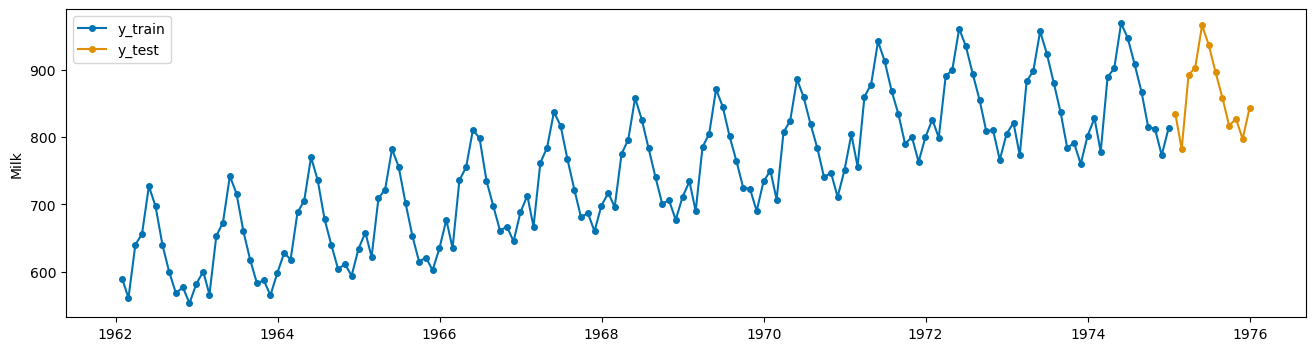

In [4]:
df.index = pd.date_range(start = '1962-01-01',periods = len(df),freq = 'ME') # time indexing must for sktime
y =df['Milk']
y_train,y_test = temporal_train_test_split(y,test_size=12)
plot_series(y_train,y_test,labels=["y_train","y_test"])
plt.legend()
plt.show()

In [5]:
forecaster= AutoARIMA(sp =12,d=0,max_p=3,max_q=3,max_P=3,max_D=1,max_Q=3,suppress_warnings=True,trace=True)
forecaster.fit(y_train)

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[12] intercept   : AIC=1000.136, Time=1.07 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=1218.095, Time=0.02 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=1015.855, Time=0.26 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=1104.312, Time=0.25 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=1349.320, Time=0.03 sec
 ARIMA(2,0,2)(0,1,1)[12] intercept   : AIC=998.169, Time=0.68 sec
 ARIMA(2,0,2)(0,1,0)[12] intercept   : AIC=1038.230, Time=0.30 sec
 ARIMA(2,0,2)(0,1,2)[12] intercept   : AIC=1000.125, Time=1.74 sec
 ARIMA(2,0,2)(1,1,0)[12] intercept   : AIC=1012.395, Time=0.63 sec
 ARIMA(2,0,2)(1,1,2)[12] intercept   : AIC=inf, Time=3.22 sec
 ARIMA(1,0,2)(0,1,1)[12] intercept   : AIC=996.457, Time=0.55 sec
 ARIMA(1,0,2)(0,1,0)[12] intercept   : AIC=1036.989, Time=0.16 sec
 ARIMA(1,0,2)(1,1,1)[12] intercept   : AIC=998.423, Time=0.60 sec
 ARIMA(1,0,2)(0,1,2)[12] intercept   : AIC=998.411, Time=1.06 sec
 ARIMA(1,0,2)(1,1,0)[12] int

AutoARIMA(d=0, max_P=3, max_Q=3, max_p=3, max_q=3, sp=12,
          suppress_warnings=True, trace=True)

c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)
c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)
c:\Users\dbda.STUDENTSDC

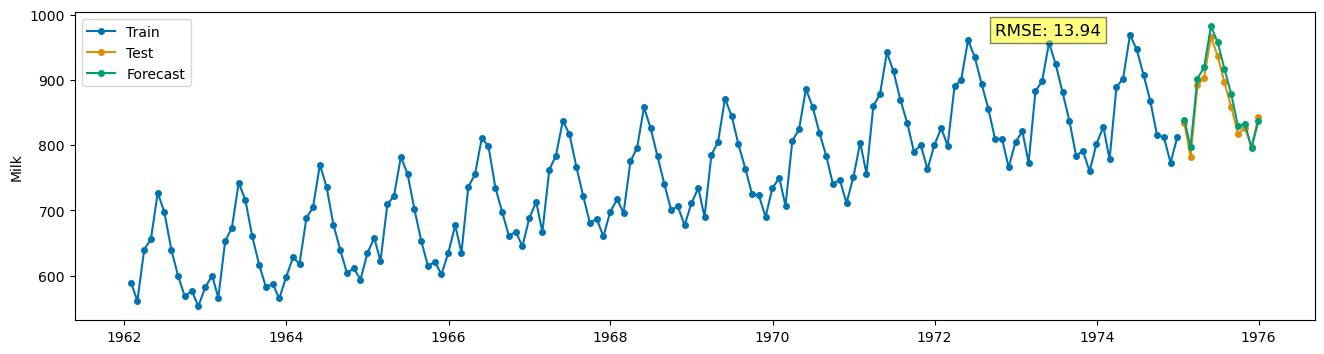

In [6]:
y_pred = forecaster.predict(fh=np.arange(1,len(y_test)+1))
rmse = MeanSquaredError(square_root=True)
plot_series(y_train,y_test,y_pred,labels=["Train","Test","Forecast"])
plt.text(y.index[-40],max(y),f'RMSE: {rmse(y_test,y_pred):.2f}',fontsize =12,bbox=dict(facecolor='yellow', alpha=0.5))
plt.legend()
plt.show()